# AML: loom-to-velocity PairScorer treatment workflow

## Biological idea and study design

Treatment may reduce the abundance of an immature compartment without redirecting its differentiation. We therefore inspect the measured RNA-velocity field, root affinity, discounted reach and coverage together, rather than treating a change in cell counts as a fate decision.

This workflow uses the genuine `Pollyea_merged.loom` splicing counts reconstructed by Ranek and colleagues ([Zenodo 6587903](https://doi.org/10.5281/zenodo.6587903)) and the original [GSE116481](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE116481) annotations. It compares baseline with day 2 after venetoclax plus azacitidine. Day 4 has only five annotated root cells and is shown in the source composition table rather than included in the primary fit.

**One patient is not a replicated treatment study.** The source label “Blasts and Immature Eryth” mixes biological identities, and malignant genotype is not available per cell. Monocytic and erythroid outcomes are annotation-defined states. This notebook demonstrates an end-to-end descriptive PairScorer analysis, not proof of malignant-blast differentiation or a causal treatment effect.

## Environment and reproducible settings

In [1]:
from pathlib import Path
import sys

PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))

In [2]:
from pathlib import Path
import sys
import importlib.metadata as metadata

import anndata as ad
import numpy as np
import pandas as pd
import scanpy as sc
import scvelo as scv
import matplotlib.pyplot as plt
from scipy import sparse
from IPython.display import display
import scCS
from benchmarks.validation.velocity_inputs import audit_counts, write_verified_loom

SEED = 19
DATA = PROJECT / "data" / "validation"
OUTPUT_DIR = PROJECT / "tutorial_outputs" / "aml_pair_velocity"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for package in ["scCS-py", "scanpy", "scvelo", "anndata"]:
    print(package, metadata.version(package))
plt.rcParams.update({"figure.dpi": 90, "figure.figsize": (7, 4)})

scCS-py 1.0.1.dev0
scanpy 1.12.6
scvelo 0.3.4
anndata 0.13.4


## 1. Load and audit real loom counts

The loader verifies the published loom checksum and joins annotations using **sample plus barcode**, because barcode sequences can recur at different time points. To keep loading practical, it reads only mapped cells and a reproducible count-variability gene screen, retaining prespecified marker genes. The source composition table is calculated before selecting the analysis compartment. No control/treated labels or transition perturbations are simulated.

In [3]:
from benchmarks.validation.data import load_aml, fetch

print("Original loom:", fetch("aml_loom", DATA))
raw = load_aml(DATA, n_genes=2000)
composition = pd.crosstab(raw.obs.cell_type, raw.obs["sample"])
display(composition)
composition.to_csv(OUTPUT_DIR / "source_composition.csv")
labels = {
    "Blasts and Immature Eryth": "Root",
    "Monocytes": "Monocytic",
    "Early Erythroids": "Erythroid",
    "Mature Erythroids": "Erythroid",
    "Macrophages": "Outside",
}
raw = raw[raw.obs.cell_type.isin(labels) & raw.obs["sample"].isin(["day0", "day2"])].copy()
raw.obs["source_state"] = raw.obs.cell_type.astype(str)
raw.obs["condition"] = raw.obs["sample"].astype(str)
raw.obs["clusters"] = raw.obs.cell_type.map(labels).astype(str)
display(audit_counts(raw))
display(pd.crosstab(raw.obs.source_state, raw.obs.condition))
print("Unique sample/barcode mapping:", raw.obs_names.is_unique)

Original loom: /workspace/scratch/1a48413c8396/work/scCS-1.0.1/data/validation/Pollyea_merged.loom
Unique sample/barcode mapping: True


sample,day0,day2,day4
cell_type,,,
B-Cells (IgA),17,8,10
B-Cells (IgD),122,60,58
Blasts and Immature Eryth,654,146,5
CD4 T cells,395,111,162
CD8 T cells,581,257,286
Early Erythroids,29,8,0
Macrophages,13,5,3
Mature Erythroids,12,2,1
Megakaryocytes,36,5,10


,layer,cells,genes,total_counts,nonzero_entries
0,spliced,1186,2006,4225230.0,836827
1,unspliced,1186,2006,945405.0,367074


condition,day0,day2
source_state,,
Blasts and Immature Eryth,654,146
Early Erythroids,29,8
Macrophages,13,5
Mature Erythroids,12,2
Monocytes,212,105


## 2. Read the analysis loom and verify exact count identity

For a uniform loom-based workflow we export the selected **measured** counts, then verify that cell IDs, gene IDs and both layers survive the round trip exactly. The output loom is an analysis subset, not a new raw-read quantification. Existing mismatched count files raise an error rather than silently substituting different input. The generated file is local data and is not bundled into the package.

In [4]:
LOOM_PATH = DATA / "aml_day0_day2_counts_g2000.loom"
write_verified_loom(raw, LOOM_PATH)
adata = ad.read_loom(LOOM_PATH, obs_names="CellID", var_names="Gene", sparse=True)
display(audit_counts(adata))
print("Verified analysis loom:", LOOM_PATH)
del raw

Verified analysis loom: /workspace/scratch/1a48413c8396/work/scCS-1.0.1/data/validation/aml_day0_day2_counts_g2000.loom


,layer,cells,genes,total_counts,nonzero_entries
0,spliced,1186,2006,4225230.0,836827
1,unspliced,1186,2006,945405.0,367074


## 3. Fit RNA velocity in expression space

The velocity estimator sees the measured spliced/unspliced layers and the native expression-neighbor graph. It never sees the scCS star coordinates. This tutorial uses a deterministic steady-state scVelo fit as an explicit baseline; it does not claim to reproduce a published dynamical or Bayesian model. The model choice, count filtering, neighborhood and gene screen are assumptions to inspect before interpreting fate scores. A matching UMAP is recomputed for visualization only.

In [5]:
# Processing uses measured spliced/unspliced molecules, before any scCS display.
scv.pp.filter_genes(adata, min_shared_counts=10)
scv.pp.normalize_per_cell(adata)
sc.pp.log1p(adata)
sc.pp.pca(adata, n_comps=30, random_state=SEED)
sc.pp.neighbors(adata, n_neighbors=30, n_pcs=30, random_state=SEED)
sc.tl.umap(adata, random_state=SEED)
scv.pp.moments(adata, n_neighbors=None, n_pcs=None)
scv.tl.velocity(adata, mode="deterministic")
scv.tl.velocity_graph(adata, n_jobs=1, show_progress_bar=False)
scv.tl.velocity_confidence(adata)
transition = scCS.get_scvelo_transition_matrix(adata)
adata.obsp["T_velocity"] = transition
print("Fitted velocity genes:", int(adata.var.velocity_genes.sum()))
display(
    adata.obs.groupby("condition", observed=True)[["velocity_length", "velocity_confidence"]].agg(
        ["median", "mean"]
    )
)
assert transition.shape == (adata.n_obs, adata.n_obs)
assert np.isfinite(transition.data).all()

Filtered out 172 genes that are detected 10 counts (shared).
Normalized count data: X, spliced, unspliced.
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
computing velocities
    finished (0:00:00) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
computing velocity graph (using 1/9 cores)
    finished (0:00:00) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)
--> added 'velocity_length' (adata.obs)
--> added 'velocity_confidence' (adata.obs)
--> added 'velocity_confidence_transition' (adata.obs)
Fitted velocity genes: 396


velocity_length            velocity_confidence          
                   median       mean              median      mean
condition                                                         
day0               11.625  12.554076            0.743056  0.705640
day2               11.880  14.586316            0.756708  0.715156

## 4. Inspect the native field and phase portraits

Arrows are estimated from the fitted RNA-velocity model. Smoothness in a stream plot and agreement among neighbors are diagnostics, not independent evidence of correct cell fate. The phase portraits use the two highest-R-squared velocity genes; they are selected for fit inspection, not because their arrows support a desired treatment narrative. The displayed source annotations and sampled conditions let you assess overlap and gross inconsistencies.

computing velocity embedding
    finished (0:00:00) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)
Phase portraits selected by velocity fit R-squared: [np.str_('AC104389.5'), np.str_('HBB')]


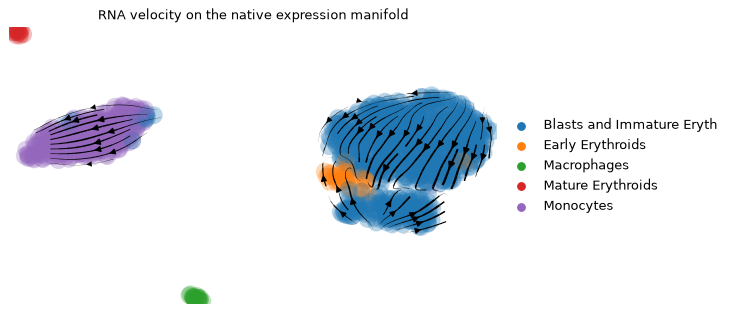

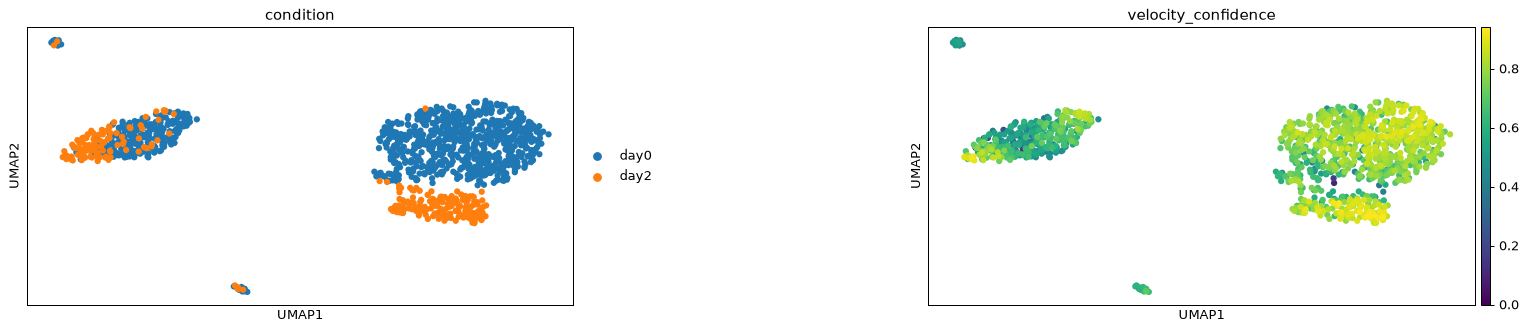

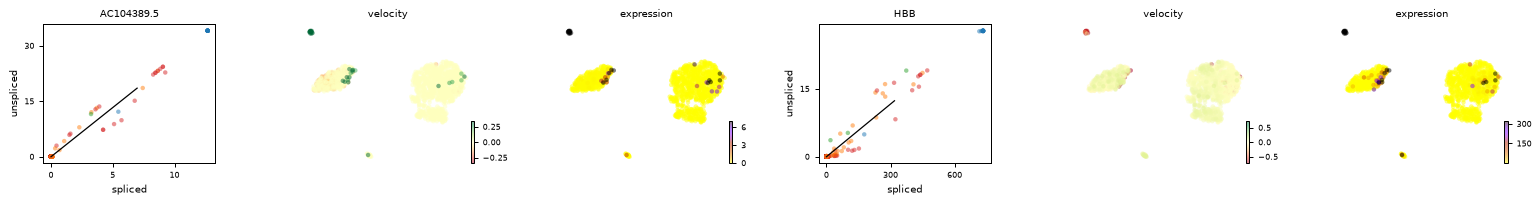

In [6]:
scv.pl.velocity_embedding_stream(
    adata,
    basis="umap",
    color="source_state",
    legend_loc="right margin",
    title="RNA velocity on the native expression manifold",
    show=False,
)
plt.show()
sc.pl.umap(adata, color=["condition", "velocity_confidence"], wspace=0.5, show=False)
plt.show()
phase_genes = (
    adata.var.loc[adata.var.velocity_genes]
    .sort_values("velocity_r2", ascending=False)
    .head(2)
    .index.tolist()
)
print("Phase portraits selected by velocity fit R-squared:", phase_genes)
if phase_genes:
    scv.pl.velocity(adata, var_names=phase_genes, ncols=2, show=False)
    plt.show()

## 5. Define the supervised question and ordering

The combined blast/immature-erythroid annotation is the root. Monocytes and erythroid cells define the selected outcomes; macrophages remain background graph context. A fixed mature-minus-immature marker score supplies the ordering, as in the initial AML pilot. It combines different maturation programs and must be checked against the displayed annotations. It is not an independent validation target, and it is not optimized to increase fate coverage.

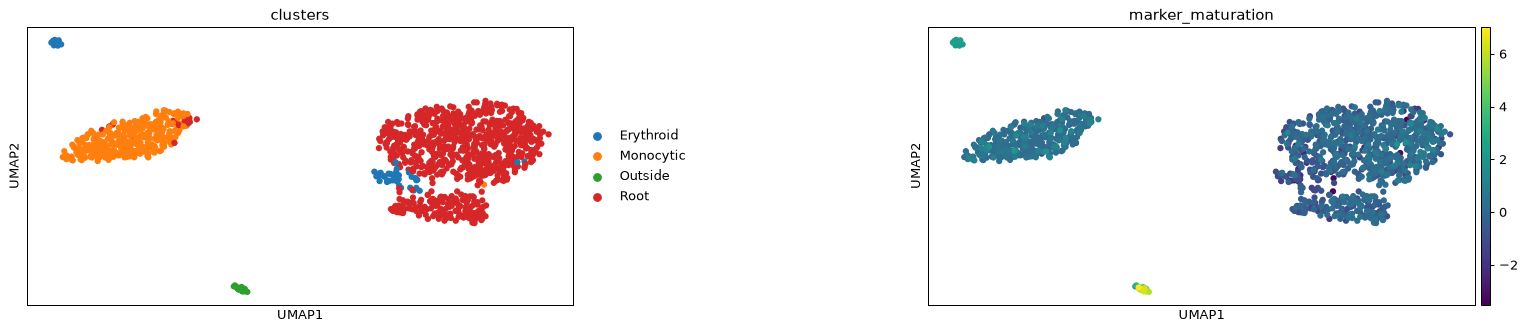

In [7]:
ROOT_LABEL = "Root"
FATES = ["Monocytic", "Erythroid"]
REPLICATE_KEY = "patient"
MARKER_GENES = ["CD34", "LYZ"]


# A predefined expression proxy: it is not physical time or clonal ground truth.
def marker_score(genes):
    present = [gene for gene in genes if gene in adata.var_names]
    if not present:
        raise ValueError("Required maturation markers are absent.")
    x = adata[:, present].X
    x = x.toarray() if sparse.issparse(x) else np.asarray(x)
    return ((x - x.mean(0)) / (x.std(0) + 1e-8)).mean(1)


adata.obs["marker_maturation"] = marker_score(
    ["LYZ", "S100A8", "CTSS", "GATA1", "KLF1", "HBB"]
) - marker_score(["CD34", "KIT", "GATA2"])
ORDERING_KEY = "marker_maturation"
adata.obs["clusters"] = pd.Categorical(adata.obs.clusters)
sc.pl.umap(adata, color=["clusters", ORDERING_KEY], wspace=0.5, show=False)
plt.show()

## 6. Preflight, shared geometry and PairScorer

The pooled fit uses one graph, ordering and anchor definition for both conditions. Background states remain in the native graph even though the supervised display contains the selected root and fates. `min_replicates=1` permits descriptive score summaries only; it does not authorize formal inference with one patient or missing independent-replicate metadata. The preflight replication errors are retained as such, while structural errors stop execution. Inspect the post-fit report for dead ends, unreachable outcomes and defined-affinity coverage.

In [8]:
pair = scCS.PairScorer(
    adata,
    root=ROOT_LABEL,
    branches=FATES,
    obs_key="clusters",
    condition_obs_key="condition",
    replicate_obs_key=REPLICATE_KEY,
    condition_order=["day0", "day2"] if REPLICATE_KEY == "patient" else ["day2", "day4"],
)
report = pair.preflight(ordering_metric=ORDERING_KEY, check_velocity=True)
report.display()
expected_design_errors = {f"condition_{condition}_replicates" for condition in pair.conditions}
unexpected = [d for d in report.errors if d.code not in expected_design_errors]
if unexpected:
    raise ValueError("Structural preflight failure: " + "; ".join(d.message for d in unexpected))
if report.errors:
    print("Replication errors remain: descriptive scoring only; formal inference is unavailable.")
pair.build_embedding(ordering_metric=ORDERING_KEY, cache_subset=False, verbose=False)
FUTURE_OPTIONS = {"effective_horizon": 64, "anchor_quantile": 0.9, "min_anchor_cells": 3}
pair.fit(
    transition_matrix=transition,
    scoring_mode="future_fate",
    transition_scope="pooled",
    future_fate_options=FUTURE_OPTIONS,
    verbose=False,
)
results = pair.score_all_conditions(
    population="root", min_cells=5, min_replicates=1, write_to_adata=False, verbose=False
)
postflight = pair.preflight(ordering_metric=ORDERING_KEY, check_velocity=True)
postflight.display()
unexpected = [d for d in postflight.errors if d.code not in expected_design_errors]
if unexpected:
    raise ValueError("Post-fit structural failure: " + "; ".join(d.message for d in unexpected))
postflight.to_frame().to_csv(OUTPUT_DIR / "preflight.csv", index=False)

Replication errors remain: descriptive scoring only; formal inference is unavailable.


,level,code,message,value
0,info,furcation_valid,Root and terminal annotations are valid.,1168
1,info,root_cells,Root population contains 800 cells.,800
2,info,terminal_Monocytic,Terminal 'Monocytic' contains 317 cells.,317
3,info,terminal_Erythroid,Terminal 'Erythroid' contains 51 cells.,51
4,info,ordering_valid,Ordering metric is finite and non-constant amo...,1.0
5,info,ordering_resolution,Root ordering has 640 unique values across 800...,0.8
6,info,velocity_available,Velocity information is available.,None
7,info,condition_day0_cells,Condition 'day0' contains 920 cells.,920
8,info,condition_day2_cells,Condition 'day2' contains 266 cells.,266
9,info,replicate_labels_reused,Some raw replicate labels occur in multiple co...,[patient_1]


,level,code,message,value
0,info,furcation_valid,Root and terminal annotations are valid.,1168
1,info,root_cells,Root population contains 800 cells.,800
2,info,terminal_Monocytic,Terminal 'Monocytic' contains 317 cells.,317
3,info,terminal_Erythroid,Terminal 'Erythroid' contains 51 cells.,51
4,info,ordering_valid,Ordering metric is finite and non-constant amo...,1.0
5,info,ordering_resolution,Root ordering has 640 unique values across 800...,0.8
6,info,velocity_available,Velocity information is available.,None
7,info,graph_dead_end_nonanchors,0 selected non-anchor cells have no positive o...,0
8,warning,root_unreachable_selected_anchors,776 root cells have no graph path to selected ...,776
9,info,transition_coverage,"Root transition coverage median=1.000, q05=1.000.",1.0


## 7. Read conditional affinity together with reach and coverage

CFA averages below use only explicitly defined root cells. DFR and UFP average across every root cell in the condition. These denominators answer different questions: DFR is a mean discounted probability, not the fraction of cells that will differentiate. No undefined CFA is replaced by zero. The table prints both the numerator and denominator for defined-affinity coverage, so a high conditional CFA cannot conceal a mostly unresolved population.

,condition,n_root_cells,n_defined_CFA,defined_fraction,DFR,UFP,SOF,CFA_Monocytic,CFA_Erythroid
0,day0,654,22,0.033639,0.020113,0.979887,-0.039498,1.0,0.0
1,day2,146,2,0.013699,0.010874,0.989126,0.024464,1.0,0.0


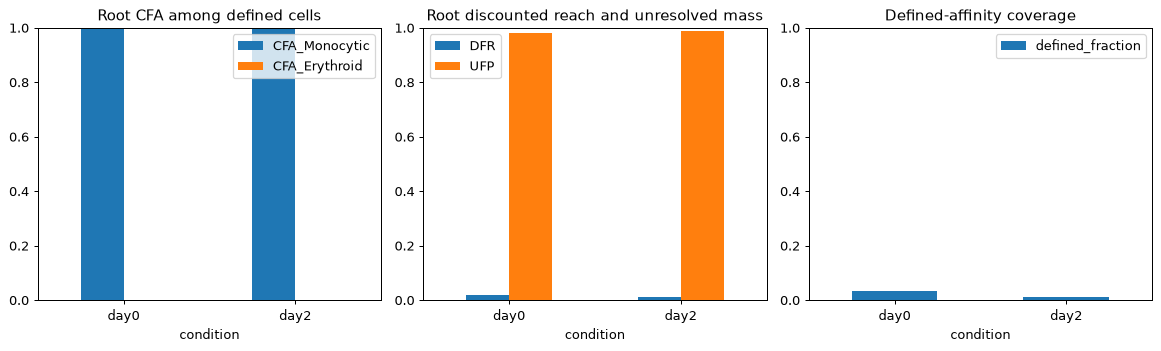

In [9]:
pooled = pair.result
rows = []
for condition, result in results.items():
    locations = pd.Index(pooled.cell_ids).get_indexer(result.cell_ids)
    assert (locations >= 0).all()
    defined = pooled.affinity_defined[locations]
    row = {
        "condition": condition,
        "n_root_cells": len(locations),
        "n_defined_CFA": int(defined.sum()),
        "defined_fraction": float(defined.mean()),
        "DFR": float(pooled.discounted_fate_reach[locations].mean()),
        "UFP": float(pooled.unresolved_probability[locations].mean()),
        "SOF": float(pooled.signed_progression[locations].mean()),
    }
    for j, fate in enumerate(pooled.fate_names):
        row["CFA_" + fate] = (
            float(pooled.conditional_fate_affinity[locations[defined], j].mean())
            if defined.any()
            else np.nan
        )
    rows.append(row)
summary = pd.DataFrame(rows)
display(summary)
summary.to_csv(OUTPUT_DIR / "condition_summary.csv", index=False)
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
summary.set_index("condition")[["CFA_" + f for f in FATES]].plot.bar(ax=axes[0], ylim=(0, 1))
summary.set_index("condition")[["DFR", "UFP"]].plot.bar(ax=axes[1], ylim=(0, 1))
summary.set_index("condition")[["defined_fraction"]].plot.bar(ax=axes[2], ylim=(0, 1))
axes[0].set_title("Root CFA among defined cells")
axes[1].set_title("Root discounted reach and unresolved mass")
axes[2].set_title("Defined-affinity coverage")
for axis in axes:
    axis.tick_params(axis="x", rotation=0)
fig.tight_layout()
plt.show()

## 8. Compare conditions on the same star

These are shared-geometry displays of the native-graph results. Refitting dynamics in the star would change the model and is not performed. Inspect population identity, the first fate's CFA, selected-fate reach, unresolved probability and Signed Ordering Flux (SOF). SOF describes movement relative to the chosen ordering; it is not an independent measurement of chronological maturation.

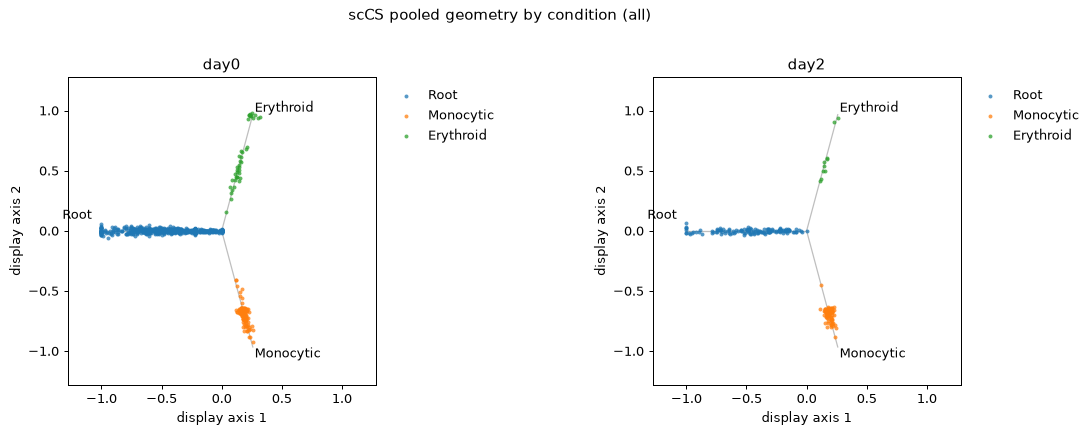

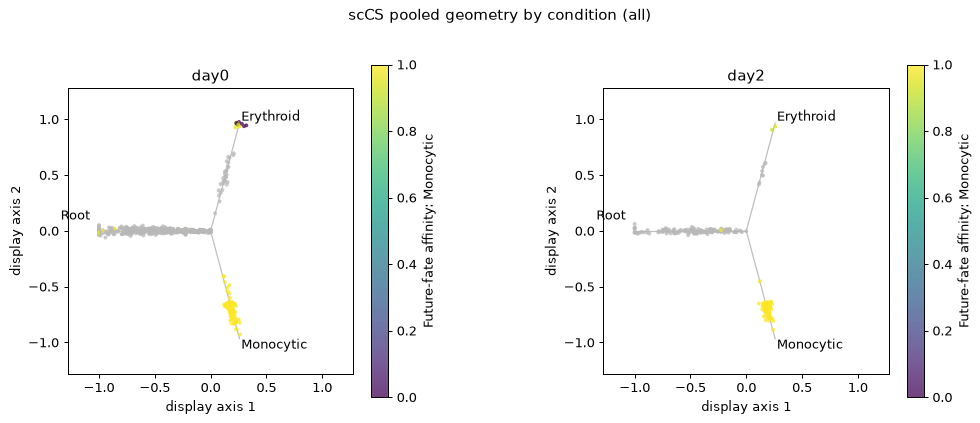

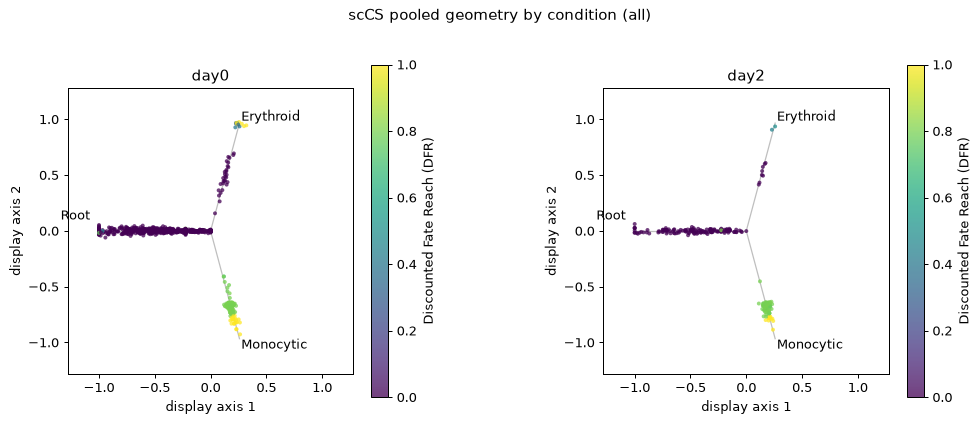

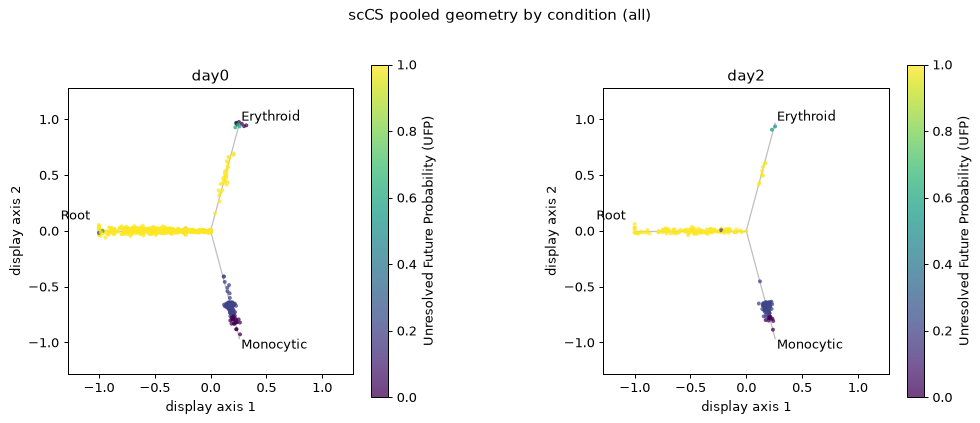

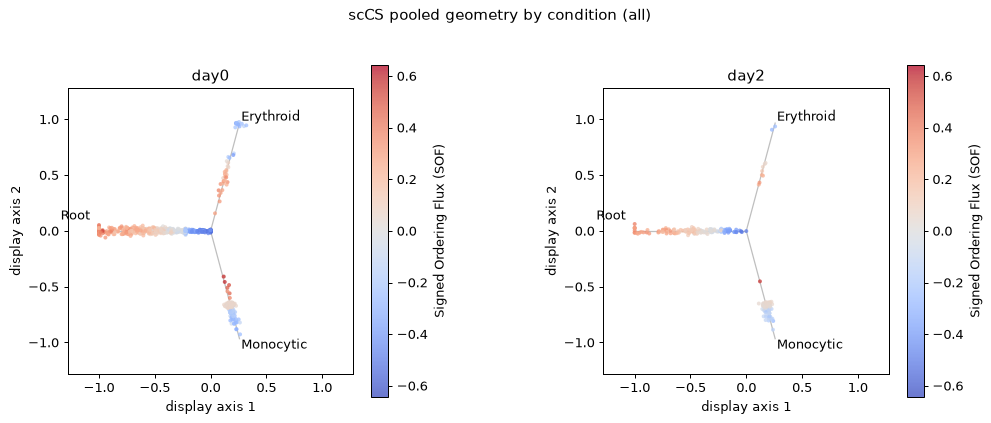

In [10]:
for color_by in [
    "population",
    "future_fate_affinity:" + FATES[0],
    "future_fate_reach",
    "unresolved_future_probability",
    "signed_progression",
]:
    figure = pair.plot_star_grid(
        results, color_by=color_by, population="all", ncols=2, figsize_per_panel=(6.4, 4.8)
    )
    if color_by == "population":
        figure.subplots_adjust(wspace=0.9)
    plt.show()

## 9. Inspect status, transition coverage and expression

Status and mean root graph-coverage plots help distinguish missing information from a conditional preference. The coverage bars have no replicate confidence intervals. Marker expression is shown from the normalized, log-transformed `X` matrix on a shared color scale. These panels are descriptive checks rather than differential-expression tests or proof that a root cell produced a particular descendant.

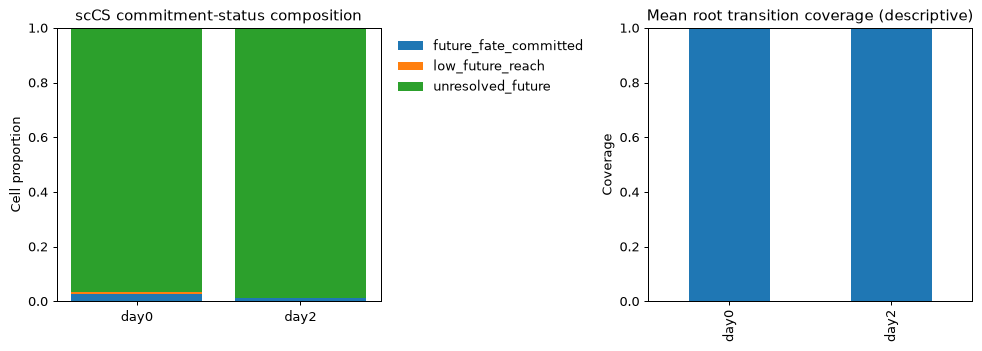

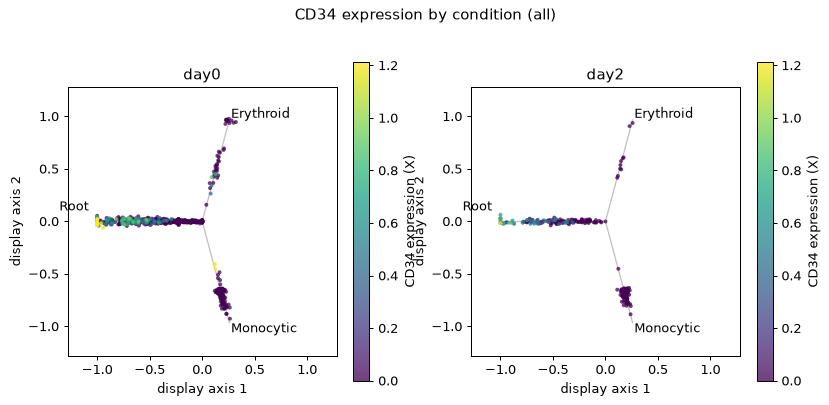

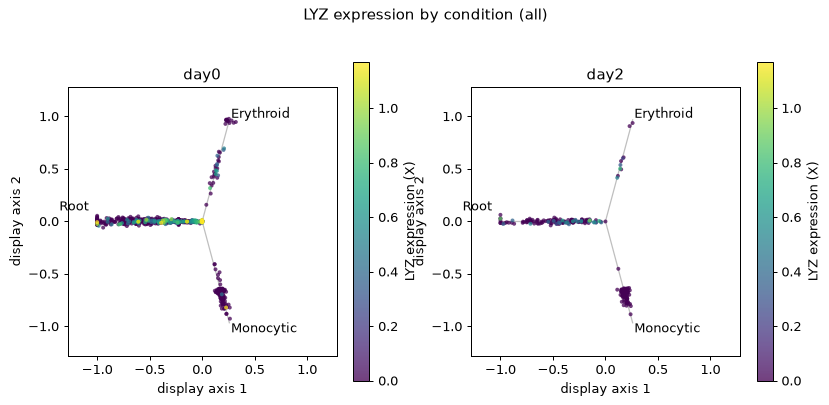

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
pair.plot_status_composition(results, ax=axes[0])
coverage_means = pd.Series(
    {name: np.mean(value.transition_coverage) for name, value in results.items()}
)
coverage_means.plot.bar(ax=axes[1], ylim=(0, 1))
axes[1].set_title("Mean root transition coverage (descriptive)")
axes[1].set_ylabel("Coverage")
fig.tight_layout()
plt.show()
for gene in MARKER_GENES:
    if gene in adata.var_names:
        pair.plot_gene_expression_star_grid(
            gene, results, shared_scale=True, ncols=2, figsize_per_panel=(5.3, 4.6)
        )
        plt.show()

## 10. Sensitivity to borrowing between conditions

The pooled graph can borrow neighbors across conditions. Blocking cross-condition transitions tests a different graph assumption while retaining the same velocity fit and supervised outcome definition. It does not refit scVelo independently in each condition. Lower reach after blocking can result from lost graph connections; it is not automatically evidence for biological arrest.

In [12]:
scope_rows = []
for scope in ["pooled", "condition"]:
    sensitivity = scCS.PairScorer(
        adata,
        root=ROOT_LABEL,
        branches=FATES,
        obs_key="clusters",
        condition_obs_key="condition",
        replicate_obs_key=REPLICATE_KEY,
        condition_order=list(results),
    )
    sensitivity.build_embedding(ordering_metric=ORDERING_KEY, cache_subset=False, verbose=False)
    sensitivity.fit(
        transition_matrix=transition,
        scoring_mode="future_fate",
        transition_scope=scope,
        future_fate_options=FUTURE_OPTIONS,
        verbose=False,
    )
    condition_results = sensitivity.score_all_conditions(
        population="root", min_cells=5, min_replicates=1, write_to_adata=False, verbose=False
    )
    for condition, result in condition_results.items():
        scope_rows.append(
            {
                "scope": scope,
                "condition": condition,
                "DFR": float(np.mean(result.commitment_strength)),
                "UFP": float(np.mean(result.unresolved_probability)),
                "defined_fraction": float(np.mean(result.affinity_defined)),
            }
        )
scope_summary = pd.DataFrame(scope_rows)
display(scope_summary)
scope_summary.to_csv(OUTPUT_DIR / "transition_scope_sensitivity.csv", index=False)

,scope,condition,DFR,UFP,defined_fraction
0,pooled,day0,0.020113,0.979887,0.033639
1,pooled,day2,0.010874,0.989126,0.013699
2,condition,day0,0.020322,0.979678,0.033639
3,condition,day2,0.010363,0.989637,0.013699


## 11. Respect the experimental unit

The source metadata are retained without inventing donors from cells, library batches, time points or clone barcodes. A formal PairScorer comparison is attempted below to show that the unsupported design is rejected. The appropriate output here is descriptive scores with explicit coverage. Independent biological replication, and an analysis that respects any pairing, would be required for population-level treatment inference.

In [13]:
# Requesting a formal test must fail rather than use cells as independent replicates.
try:
    pair.compare_conditions(results, metric="future_fate_reach", verbose=False)
except ValueError as error:
    print("Formal inference is unavailable for this design:", error)
    inference_refused = True
else:
    raise AssertionError("This descriptive design must not produce a treatment p-value.")

Formal inference is unavailable for this design: At least two defined biological replicates per condition are required; included counts={'day0': 1, 'day2': 1}, requested counts={'day0': 1, 'day2': 1}; excluded replicates=[].


## 12. Export and interpretation

The analysis object stores the actual splicing layers after normalization, fitted velocity vectors, native neighbor graph, UMAP, ordering and scCS scores. The source count files and checksums remain the reference for raw molecules. CSV exports record the condition summaries, graph-scope sensitivity and velocity diagnostics. Figures are retained in this executed notebook for Read the Docs.

In [14]:
pair.result.write_to_adata(adata)
adata.write_h5ad(OUTPUT_DIR / "pair_scorer_velocity_analysis.h5ad")
adata.obs[
    ["condition", "source_state", "velocity_length", "velocity_confidence", ORDERING_KEY]
].to_csv(OUTPUT_DIR / "velocity_and_ordering_qc.csv")
assert inference_refused
assert summary.n_root_cells.gt(0).all()
assert summary.defined_fraction.between(0, 1).all()
assert np.isfinite(adata.layers["velocity"]).all()
print(
    "Saved fitted velocity, scCS scores, figures in notebook outputs, and QC tables to", OUTPUT_DIR
)

Saved fitted velocity, scCS scores, figures in notebook outputs, and QC tables to /workspace/scratch/1a48413c8396/work/scCS-1.0.1/tutorial_outputs/aml_pair_velocity


## Reading the recorded result

With the recorded settings, baseline has **22/654** root cells with defined CFA (3.36%), while day 2 has **2/146** (1.37%). Mean root DFR is approximately **0.0201** and **0.0109**, respectively. The defined subset has monocytic CFA 1.0 in both conditions, which cannot be interpreted as a monocytic prediction for every root cell. Condition-blocked graphs retain similarly low coverage.

The native velocity map places much of the immature compartment apart from the monocytic and mature erythroid populations. This visual separation and the reach diagnostics identify a weakly supported root-to-outcome analysis, not proof that treatment blocks differentiation. The single-patient design and mixed root annotation remain additional limitations.

## What the result can support

Read the executed root counts, defined-CFA counts and reach before describing a condition difference. When outcomes are reachable from only a small root subset, a monocytic CFA of one does not describe all blasts. Native velocity and phase-portrait plots make that limitation inspectable, alongside the mixed root annotation, single-patient design or absence of independent fate measurements.

A defensible conclusion is a description of the inferred state associations under the stated graph and ordering. A treatment-induced differentiation or arrest claim would require malignant-cell identification, model-quality evidence, independent biological replication and orthogonal outcome data.